# Industrial operating stages S0–S8 — all day files, one day in detail

Same data and same rules as `operating_states.ipynb`, but every minute now also carries the **industry stage code**
from the stage benchmark of 2026-10-16 ([benchmark page](https://claude.ai/artifact/QWDAPd9fdpzdDmpUeebjFN)):
IEC 62282-3-200 (cold state, pre-generation state), the SOFC S0–S8 sequence ladder, PackML / ISA-88 and
power-plant start classes.

* **Nothing in `operating_states.py` changes.** The codes are a layer on top of today's stage and Shut-down sub-stage.
* **One new stage, S8 Trip**: a protective cut of a hot plant, taken from the 1 s trip analysis (`trip_check.py`,
  section 11 of `operating_states.ipynb`). Today those minutes are filed under Part load, Thermal adjustment, Hot standby or Shut-down.
* **Start class** (cold / warm / hot) for every S2 Start-up, as power plants class their starts.

The logic lives in `industrial_stages.py` (same folder); `python 03_data_analysis/scripts/industrial_stages.py` gives the same
labels. Outputs go to `industrial_stages/`.

**The four benchmark decisions are still open.** This notebook follows the recommended choices where they agree with
showing the codes (A: codes shown next to today's names; C: start class added) and shows both readings where they do not
(B: S8 is a stage here *and* a `trip` flag column; D: S0 is shown as its own code but stays Shut-down · At ambient in
`operating_states.py`, so stage folders, generator and checker are untouched).

In [1]:
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import industrial_stages as ind
import operating_states as ops

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)

DAY = "20260324"  # day shown in detail: Hot standby, part load, two trips, shut-down

## 1. The nine stages and how each one is read from the data

| Code | Stage | Today in `operating_states.py` | Rule (unchanged) |
|---|---|---|---|
| **S0** | Cold, plant off | Shut-down · *At ambient (plant off)* | no current, heater off, air off, stack ≤ ambient + 30 K |
| **S1** | Warm, plant off | Idle | plant off, stack > ambient + 30 K, no Shut-down before it |
| **S2** | Start-up | Start-up | heater on with air / stack rising > 10 °C/h, below the operating window; incl. air purge, intermediate hold < 6 h, heat-up pauses |
| **S3** | Hot standby | Hot standby | no load, \|dT/dt\| < 5 °C/h, ≥ 550 °C, or 450–550 °C held ≥ 6 h; incl. fuel switch-over and pre-load |
| **S4** | Thermal adjustment | Thermal adjustment | hot, no load, temperature moving (re-heat / cool-back) |
| **S5** | Part load | Part load | string current ≥ 1 A for ≥ 3 min, below 28.5 A |
| **S6** | Rated power | Rated power | ≥ 28.5 A per string (95 % of 30 A) — never reached |
| **S7** | Shut-down | Shut-down · *Cooling* | load to zero, forced or natural cooling, stack still warm |
| **S8** | **Trip** (proposed) | not a stage | see below |

**S8 Trip.** A trip is an abrupt cut found in the 1 s data (`trip_check.cut_events()`) of one of three kinds, with the
stack at ≥ 400 °C:

* **EMERGENCY PURGE**: S-PLC purge pattern, stack contactors and heater cut together,
* **EMERGENCY STOP**: all supply valves shut, only NG vent MV1.4.4 open, compressor off,
* **Power cut at trip value, gas unchanged**: current / heater cut within 60 s of a trip sensor above its limit.

Cuts less than 30 min apart are one trip (e.g. purge → stop → reset). S8 runs from the first whole minute after the first cut to
15 min after the last one; by then the cool-down is under way and the minutes return to their normal code. A
load ramp-down that was already running when the cut came keeps its S7 label: the trip starts at the cut, not before.

**Start class** of an S2 episode, from the stack temperature at its first minute: **cold** ≤ ambient + 30 K (the S0 test),
**hot** ≥ 450 °C (Hot standby lower bound), **warm** in between.

The table as the module holds it:

In [2]:
pd.DataFrame(
    {"stage": ind.NAMES, "industry name": ind.INDUSTRY, "today": ind.TODAY}
).rename_axis("code")

,stage,industry name,today
code,,,
S0,"Cold, plant off",Cold state / Stopped / Offline cold,Shut-down · At ambient
S1,"Warm, plant off",Offline warm (power plants only),Idle
S2,Start-up,Start-up / Starting / Heat-up,Start-up
S3,Hot standby,Pre-generation / Hot standby / Idle,Hot standby
S4,Thermal adjustment,No standard name (PackML Holding is closest),Thermal adjustment
S5,Part load,"Power generation, partial / Execute",Part load
S6,Rated power,"Power generation, rated",Rated power
S7,Shut-down,Shutdown / Stopping / Normal shutdown,Shut-down · Cooling
S8,Trip,Emergency shutdown / Aborted / Unit trip,(not a stage: Part load / Hot standby / Shut-d...


In [3]:
pd.Series(
    {
        "trip kinds": ", ".join(ind.TRIP_KINDS),
        "stack T at the cut ≥ (°C)": ind.TRIP_T_MIN,
        "cuts joined if closer than (min)": ind.TRIP_CHAIN_MIN,
        "S8 lasts after the last cut (min)": ind.TRIP_HOLD_MIN,
        "start class: cold if T ≤ ambient + (K)": ops.DT_AMBIENT,
        "start class: hot if T ≥ (°C)": ops.T_HOT,
        "episode broken by a logger gap longer than (h)": ind.EPISODE_GAP_H,
    },
    name="value",
).to_frame()

,value
trip kinds,"EMERGENCY PURGE, EMERGENCY STOP, Power cut at ..."
stack T at the cut ≥ (°C),400.0
cuts joined if closer than (min),30
S8 lasts after the last cut (min),15
start class: cold if T ≤ ambient + (K),30.0
start class: hot if T ≥ (°C),450.0
episode broken by a logger gap longer than (h),6


## 2. Segmentation of all day files

`ind.run_all()` runs `ops.segment()` on every day file, reads the trip cuts (cached in
`operating_states/trip_cut_events.csv` by `operating_states.ipynb` §11; `run_all(recompute_trips=True)` reads the 1 s
files again) and adds three columns to every minute:

* `code` (S0–S8 or *No data*) and `ind_stage` (code + name),
* `trip` (True inside an S8 window: the flag reading of decision B).

Each day also gets a block table: one row per contiguous run of one code.

In [4]:
all_days, trips = ind.run_all()
allst = pd.concat(s for s, _ in all_days.values())
print(f"{len(all_days)} day files, {len(allst):,} minutes, {len(trips)} trips")
trips

39 day files, 55,584 minutes, 9 trips


,trip,start,end,first cut,last cut,n cuts,cuts
0,1,2026-03-13 13:45:00,2026-03-13 14:00:00,2026-03-13 13:45:15,2026-03-13 13:45:15,1,"Power cut at trip value, gas unchanged"
1,2,2026-03-19 10:49:00,2026-03-19 11:20:00,2026-03-19 10:49:49,2026-03-19 11:05:03,3,"Power cut at trip value, gas unchanged → Power..."
2,3,2026-03-19 15:54:00,2026-03-19 16:09:00,2026-03-19 15:54:35,2026-03-19 15:54:35,1,"Power cut at trip value, gas unchanged"
3,4,2026-03-24 09:25:00,2026-03-24 09:57:00,2026-03-24 09:25:26,2026-03-24 09:42:51,3,"EMERGENCY PURGE → Power cut at trip value, gas..."
4,5,2026-03-24 14:36:00,2026-03-24 14:53:00,2026-03-24 14:36:22,2026-03-24 14:38:06,2,EMERGENCY PURGE → EMERGENCY STOP
5,6,2026-03-25 08:50:00,2026-03-25 09:05:00,2026-03-25 08:50:37,2026-03-25 08:50:37,1,EMERGENCY STOP
6,7,2026-03-25 10:58:00,2026-03-25 11:13:00,2026-03-25 10:58:26,2026-03-25 10:58:26,1,"Power cut at trip value, gas unchanged"
7,8,2026-03-25 15:28:00,2026-03-25 15:43:00,2026-03-25 15:28:17,2026-03-25 15:28:17,1,EMERGENCY STOP
8,9,2026-03-30 09:30:00,2026-03-30 09:45:00,2026-03-30 09:30:57,2026-03-30 09:30:57,1,EMERGENCY STOP


In [5]:
states, blocks = all_days[DAY]
states[
    [
        "T_stack_C",
        "I_string_A",
        "P_EAPH_kW",
        "phase",
        "stage",
        "sub_stage",
        "operation",
        "code",
        "trip",
    ]
].iloc[::60]

,T_stack_C,I_string_A,P_EAPH_kW,phase,stage,sub_stage,operation,code,trip
Date Time,,,,,,,,,
2026-03-24 00:00:00,580.585000,0.000008,14.217717,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 01:00:00,580.800000,0.000000,14.428069,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 02:00:00,580.800000,0.000000,14.198359,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 03:00:00,580.905000,0.000000,14.335909,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 04:00:00,580.930000,0.000017,14.279594,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 05:00:00,580.940000,0.000017,14.041258,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 06:00:00,580.949167,0.000017,14.325051,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 07:00:00,580.900000,0.000000,14.233720,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False
2026-03-24 08:00:00,580.900000,0.000008,16.819050,Forming gas (N2 + H2),Hot standby,,Temperature hold,S3,False


In [6]:
blocks

,code,name,stage_today,operations,duration_min,start,end,T_start_C,T_end_C,I_max_A,P_EAPH_mean_kW
0,S3,Hot standby,Hot standby,Temperature hold,486,2026-03-24 00:00:00,2026-03-24 08:06:00,580.6,581.7,0.0,14.3
1,S4,Thermal adjustment,Thermal adjustment,Re-heat (no load),26,2026-03-24 08:06:00,2026-03-24 08:32:00,581.8,584.6,0.0,17.8
2,S3,Hot standby,Hot standby,Pre-load (ready for load),22,2026-03-24 08:32:00,2026-03-24 08:54:00,584.8,597.7,0.9,15.6
3,S5,Part load,Part load,Load ramp-up > Steady load > Load ramp-down,31,2026-03-24 08:54:00,2026-03-24 09:25:00,598.4,654.7,14.6,15.1
4,S8,Trip,Part load / Thermal adjustment,Load ramp-down > Cool-back (no load),32,2026-03-24 09:25:00,2026-03-24 09:57:00,656.7,643.4,6.0,0.7
5,S4,Thermal adjustment,Thermal adjustment,Cool-back (no load),58,2026-03-24 09:57:00,2026-03-24 10:55:00,643.1,631.2,0.0,6.7
6,S3,Hot standby,Hot standby,Temperature hold,147,2026-03-24 10:55:00,2026-03-24 13:22:00,631.1,628.5,0.0,11.6
7,S4,Thermal adjustment,Thermal adjustment,Cool-back (no load),24,2026-03-24 13:22:00,2026-03-24 13:46:00,628.4,622.8,0.0,10.1
8,S3,Hot standby,Hot standby,Pre-load (ready for load),8,2026-03-24 13:46:00,2026-03-24 13:54:00,622.5,623.4,1.0,14.3
9,S5,Part load,Part load,Load ramp-up,42,2026-03-24 13:54:00,2026-03-24 14:36:00,623.8,669.1,8.4,13.5


## 3. Timeline of the detailed day

Panels from top to bottom: stack temperature (median of the healthy `TIR_4_6_*`) and cathode inlet `TIRC_2_06`;
EAPH heater power and string current; anode gases N₂ / natural gas / H₂ (`FIRC_13`, `FIRC_12`, `FIRC_15`, H₂ dashed on
the right axis); cathode air `FIRC_111 + 112`; then two bands: the **industry code** and today's stage, so the two can be
compared minute by minute. Red triangles mark each trip cut.

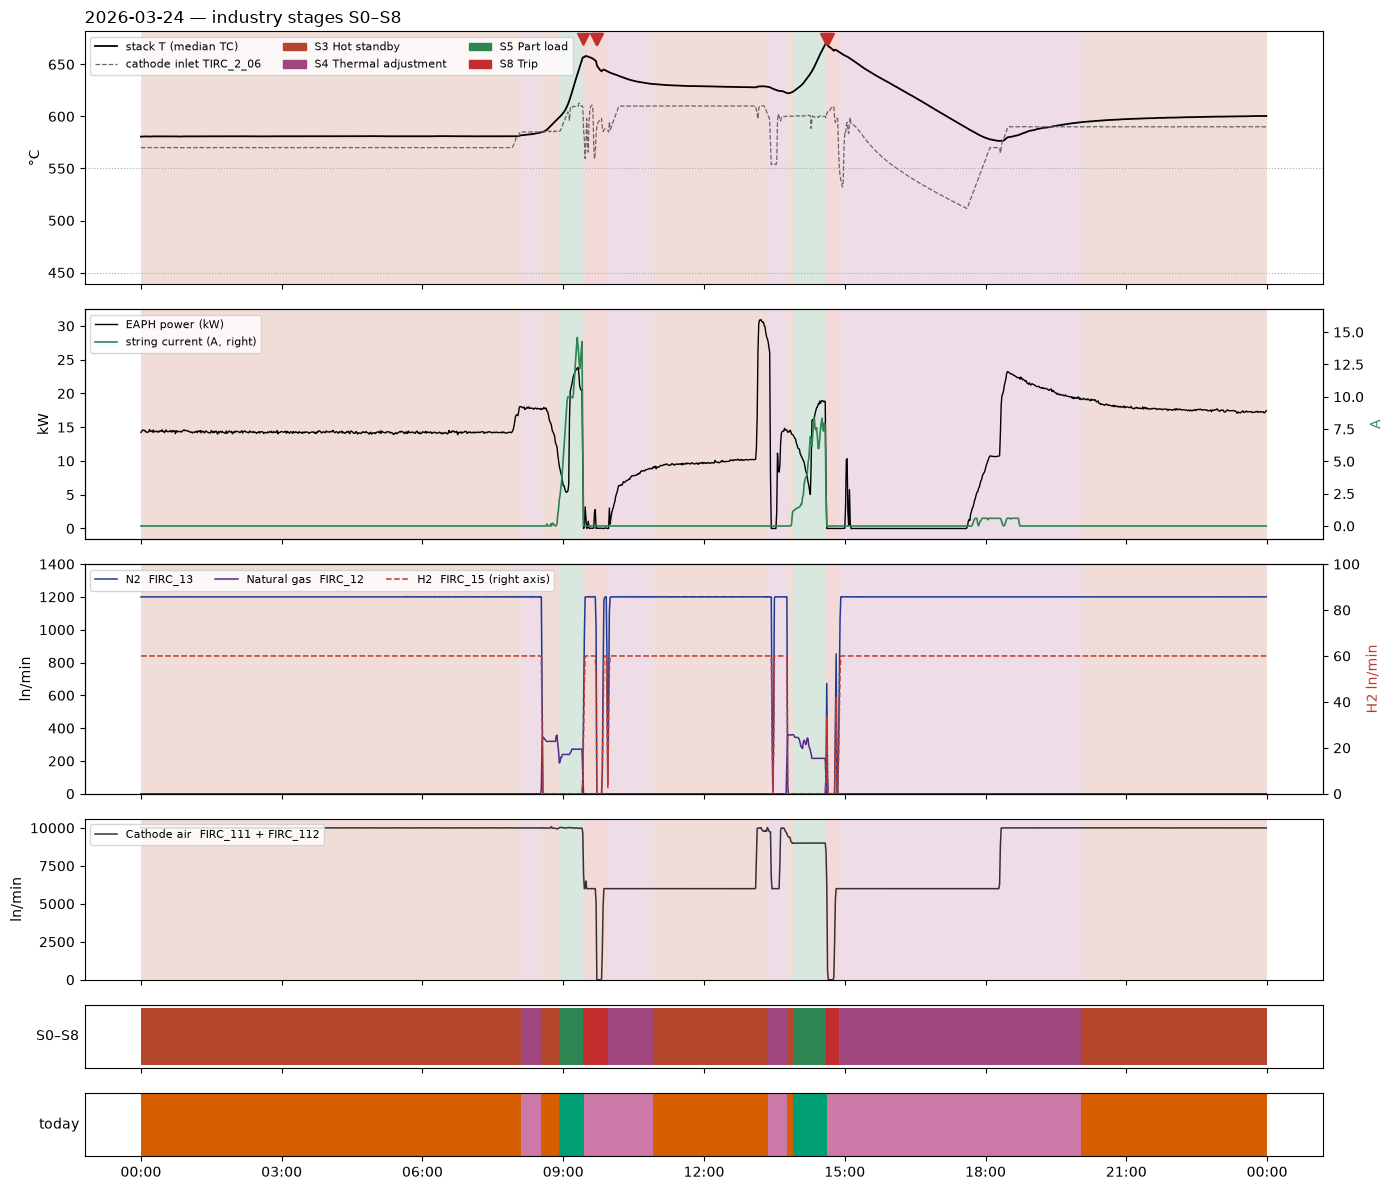

In [7]:
def day_plot(s, blk, title, cuts=None):
    fig, ax = plt.subplots(
        6,
        1,
        figsize=(14, 12),
        sharex=True,
        gridspec_kw={"height_ratios": [2.2, 2, 2, 1.4, 0.55, 0.55]},
    )
    ax[0].plot(s.index, s.T_stack_C, "k", lw=1.3, label="stack T (median TC)")
    ax[0].plot(
        s.index,
        s.T_cathode_in_C,
        color="#666",
        ls="--",
        lw=0.9,
        label="cathode inlet TIRC_2_06",
    )
    for y in (ops.T_HOT, ops.T_STANDBY):
        ax[0].axhline(y, color="#aaa", ls=":", lw=0.8)
    ax[0].set_ylabel("°C")
    ax[0].legend(fontsize=8, loc="upper left")
    ax[1].plot(s.index, s.P_EAPH_kW, "k", lw=1, label="EAPH power (kW)")
    ax[1].set_ylabel("kW")
    b = ax[1].twinx()
    b.plot(
        s.index,
        s.I_string_A,
        color=ind.COLORS["S5"],
        lw=1.2,
        label="string current (A, right)",
    )
    b.set_ylabel("A", color=ind.COLORS["S5"])
    b.set_ylim(-1, max(10, s.I_string_A.max() * 1.15))
    ax[1].legend(
        handles=ax[1].get_lines() + b.get_lines(), fontsize=8, loc="upper left"
    )
    ops.plot_flows(s, ax[2], ax[3])
    for r in blk.itertuples():
        for a in ax[:4]:
            a.axvspan(
                r.start, r.end, color=ind.COLORS.get(r.code, "#fff"), alpha=0.18, lw=0
            )
    ind.plot_band(ax[4], blk)
    tb = ops.blocks(s)
    for _, g in s.groupby(tb):
        ax[5].axvspan(
            g.index[0],
            g.index[-1] + pd.Timedelta("1min"),
            color=ops.STAGE_COLORS.get(g.stage.iloc[0], "#fff"),
            lw=0,
        )
    for a, lab in ((ax[4], "S0–S8"), (ax[5], "today")):
        a.set_yticks([])
        a.set_ylabel(lab, rotation=0, ha="right", va="center")
    for t in cuts if cuts is not None else []:
        ax[0].plot(
            t,
            0.97,
            marker="v",
            color=ind.COLORS["S8"],
            ms=9,
            transform=ax[0].get_xaxis_transform(),
        )
    ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax[0].set_title(title, loc="left")
    codes = [c for c in ind.CODES if c in set(blk.code)]
    ax[0].legend(
        handles=ax[0].get_lines()[:2] + ind.legend_handles(codes),
        fontsize=8,
        loc="upper left",
        ncol=3,
    )
    fig.tight_layout()
    return fig


ev = ind.trip_events()
day_cuts = ev.time[ev.time.dt.strftime("%Y%m%d") == DAY]
day_plot(
    states, blocks, f"{pd.Timestamp(DAY):%Y-%m-%d} — industry stages S0–S8", day_cuts
)
plt.show()

## 4. A trip in detail

The first trip of the detailed day, ±40 min. The cut takes the plant out of S5 Part load straight into S8; after 15 min
past the last cut the minutes return to the code `operating_states.py` gives them.

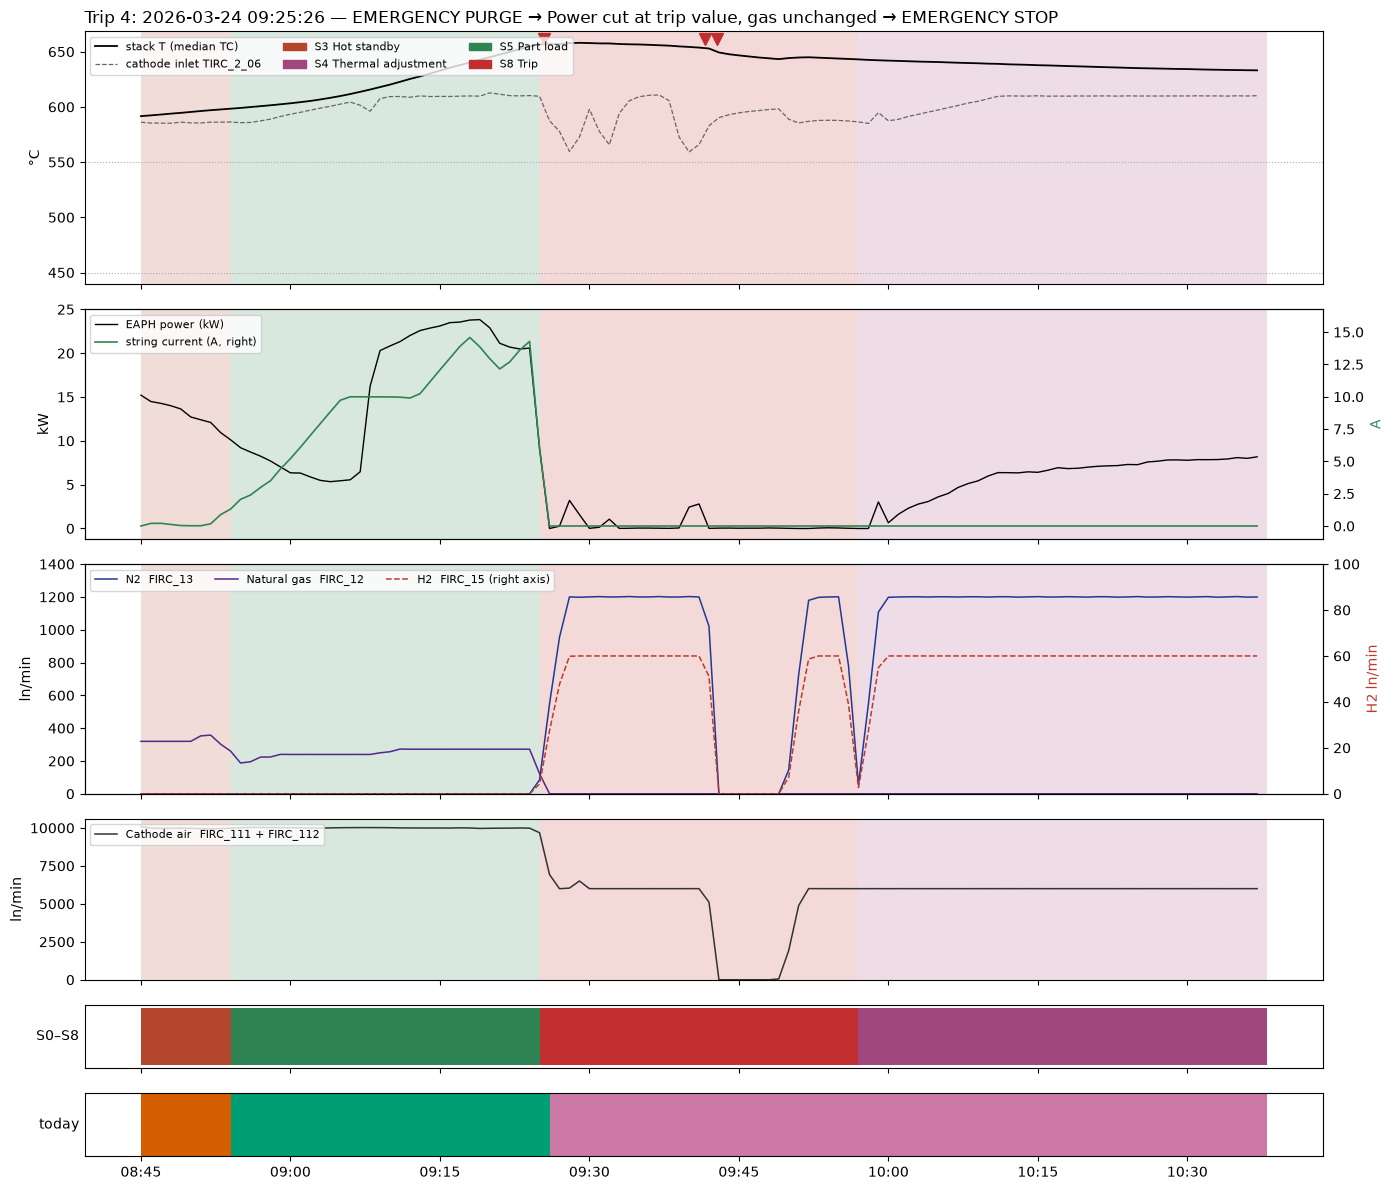

,T_stack_C,I_string_A,P_EAPH_kW,phase,stage,operation,code
Date Time,,,,,,,
2026-03-24 09:19:00,642.6,13.9,23.8,Natural gas,Part load,Load ramp-down,S5
2026-03-24 09:21:00,647.4,12.1,21.1,Natural gas,Part load,Load ramp-down,S5
2026-03-24 09:23:00,652.4,13.6,20.5,Natural gas,Part load,Load ramp-down,S5
2026-03-24 09:25:00,656.7,6.0,9.2,Natural gas,Part load,Load ramp-down,S8
2026-03-24 09:27:00,656.9,0.0,0.3,Forming gas (N2 + H2),Thermal adjustment,Cool-back (no load),S8
2026-03-24 09:29:00,658.0,0.0,1.6,Forming gas (N2 + H2),Thermal adjustment,Cool-back (no load),S8
2026-03-24 09:31:00,657.5,0.0,0.1,Forming gas (N2 + H2),Thermal adjustment,Cool-back (no load),S8
2026-03-24 09:33:00,657.0,0.0,0.0,Forming gas (N2 + H2),Thermal adjustment,Cool-back (no load),S8
2026-03-24 09:35:00,656.5,0.0,0.0,Forming gas (N2 + H2),Thermal adjustment,Cool-back (no load),S8


In [8]:
t0 = trips[trips.start.dt.strftime("%Y%m%d") == DAY].iloc[0]
win = states.loc[t0.start - pd.Timedelta("40min") : t0.end + pd.Timedelta("40min")]
day_plot(
    win,
    ind.blocks(win),
    f"Trip {t0.trip}: {t0['first cut']:%Y-%m-%d %H:%M:%S} — {t0.cuts}",
    ev.time[(ev.time >= win.index[0]) & (ev.time <= win.index[-1])],
)
plt.show()
win.loc[
    t0.start - pd.Timedelta("6min") : t0.end + pd.Timedelta("2min") : 2,
    ["T_stack_C", "I_string_A", "P_EAPH_kW", "phase", "stage", "operation", "code"],
].round(1)

## 5. Time per stage on the detailed day

In [9]:
summary = (
    blocks[blocks.code != "No data"]
    .groupby("code")["duration_min"]
    .sum()
    .to_frame("minutes")
)
summary.insert(0, "stage", summary.index.map(ind.NAMES))
summary["share_%"] = (100 * summary.minutes / summary.minutes.sum()).round(1)
summary

,stage,minutes,share_%
code,,,
S3,Hot standby,901,62.6
S4,Thermal adjustment,417,29.0
S5,Part load,73,5.1
S8,Trip,49,3.4


## 6. All day files

### 6.1 Crosswalk: today's labels → industry codes (minutes, all 39 days)

Every minute keeps its old label. This table shows where each old label went; the only splits are Shut-down
(S0 / S7) and the trip minutes taken out of four stages into S8.

In [10]:
cw = pd.crosstab(
    allst.stage.where(allst.stage != "Shut-down", "Shut-down · " + allst.sub_stage),
    allst.code,
)
cw = cw.reindex(columns=[c for c in ind.CODES + ["No data"] if c in cw.columns])
cw.index.name = "today"
cw.style.background_gradient(cmap="Greys", axis=None, vmax=3000).format("{:,d}")

code,S0,S1,S2,S3,S4,S5,S7,S8,No data
today,,,,,,,,,
Hot standby,0,0,0,"17,824",0,0,0,15,0
Idle,0,"1,258",0,0,0,0,0,0,0
No data,0,0,0,0,0,0,0,0,774
Part load,0,0,0,0,0,265,0,3,0
Shut-down · At ambient (plant off),"5,292",0,0,0,0,0,0,0,0
Shut-down · Cooling,0,0,0,0,0,0,"18,427",45,0
Start-up,0,0,"8,935",0,0,0,0,0,0
Thermal adjustment,0,0,0,0,"2,639",0,0,107,0


### 6.2 Hours per stage, all days

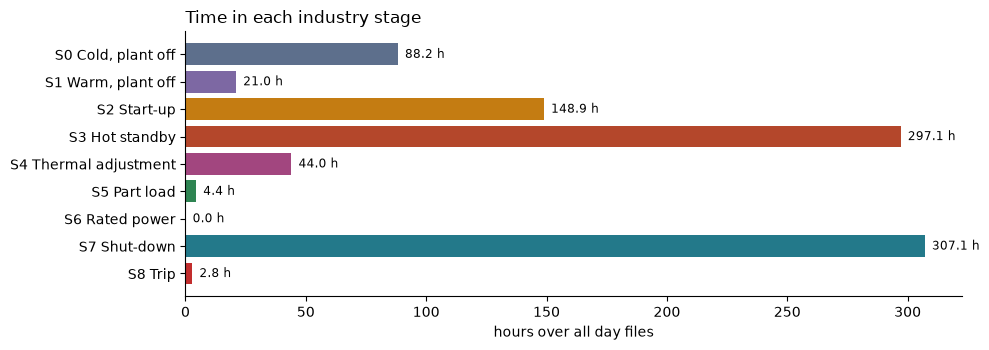

,stage,hours,share_%
code,,,
S0,"Cold, plant off",88.2,9.5
S1,"Warm, plant off",21.0,2.3
S2,Start-up,148.9,16.1
S3,Hot standby,297.1,32.1
S4,Thermal adjustment,44.0,4.7
S5,Part load,4.4,0.5
S6,Rated power,0.0,0.0
S7,Shut-down,307.1,33.1
S8,Trip,2.8,0.3


In [11]:
hours = (
    (allst.code.value_counts().reindex(ind.CODES + ["No data"], fill_value=0) / 60)
    .round(1)
    .to_frame("hours")
)
hours.insert(0, "stage", hours.index.map(lambda c: ind.NAMES.get(c, "")))
hours["share_%"] = (100 * hours.hours / hours.hours.sum()).round(1)

fig, ax = plt.subplots(figsize=(10, 3.6))
h = hours.loc[ind.CODES]
ax.barh(range(len(h)), h.hours, color=[ind.COLORS[c] for c in h.index])
ax.set_yticks(range(len(h)), [ind.LABELS[c] for c in h.index])
ax.invert_yaxis()
for i, v in enumerate(h.hours):
    ax.text(v + 3, i, f"{v:,.1f} h", va="center", fontsize=8.5)
ax.set_xlabel("hours over all day files")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Time in each industry stage", loc="left")
plt.tight_layout()
plt.show()
hours

### 6.3 Episodes

Unlike `operating_states.ipynb` §9.1, episodes here are counted on **all days joined**: a stage running across midnight
is one episode, counted on the day it started (so no separate "new starts" table is needed). A logger gap longer
than 6 h (including missing day files) ends an episode; shorter gaps are skipped.

In [12]:
eps = ind.episodes(allst)
eps["day"] = eps.start.dt.date
per_day = pd.crosstab(eps.day, eps.code).reindex(columns=ind.CODES, fill_value=0)
per_day["total"] = per_day.sum(axis=1)
per_day.loc["TOTAL"] = per_day.sum()
per_day.style.background_gradient(
    cmap="Oranges", subset=(per_day.index[:-1], ind.CODES)
).format("{:d}")

code,S0,S1,S2,S3,S4,S5,S6,S7,S8,total
day,,,,,,,,,,
2025-10-30,0,2,1,0,0,0,0,0,0,3
2025-11-13,1,0,1,0,0,0,0,1,0,3
2025-11-18,1,0,0,0,0,0,0,0,0,1
2026-01-30,1,0,1,0,0,0,0,1,0,3
2026-01-31,0,0,1,2,1,0,0,0,0,4
2026-02-02,0,0,0,1,1,0,0,0,0,2
2026-02-04,0,0,0,0,0,0,0,1,0,1
2026-02-06,1,0,0,0,0,0,0,0,0,1
2026-02-13,1,0,1,0,0,0,0,0,0,2


### 6.4 Minutes in each stage per day file

In [13]:
minutes = pd.DataFrame(
    {pd.Timestamp(d).date(): s.code.value_counts() for d, (s, _) in all_days.items()}
).T
minutes = (
    minutes.reindex(columns=ind.CODES + ["No data"], fill_value=0).fillna(0).astype(int)
)
minutes.index.name = "day"
minutes.loc["TOTAL"] = minutes.sum()
minutes

code,S0,S1,S2,S3,S4,S5,S6,S7,S8,No data
day,,,,,,,,,,
2025-10-30,0,1258,182,0,0,0,0,0,0,0
2025-11-13,647,0,645,0,0,0,0,148,0,0
2025-11-14,0,0,0,0,0,0,0,1440,0,0
2025-11-15,0,0,0,0,0,0,0,1440,0,0
2025-11-16,0,0,0,0,0,0,0,1440,0,0
2025-11-17,0,0,0,0,0,0,0,1440,0,0
2025-11-18,988,0,0,0,0,0,0,452,0,0
2026-01-30,610,0,540,0,0,0,0,290,0,0
2026-01-31,0,0,578,170,203,0,0,489,0,0


### 6.5 All days at a glance

One row per day file, 00:00 to 24:00, coloured by industry stage. White = logger gap. Number on the right = episodes
that started that day.

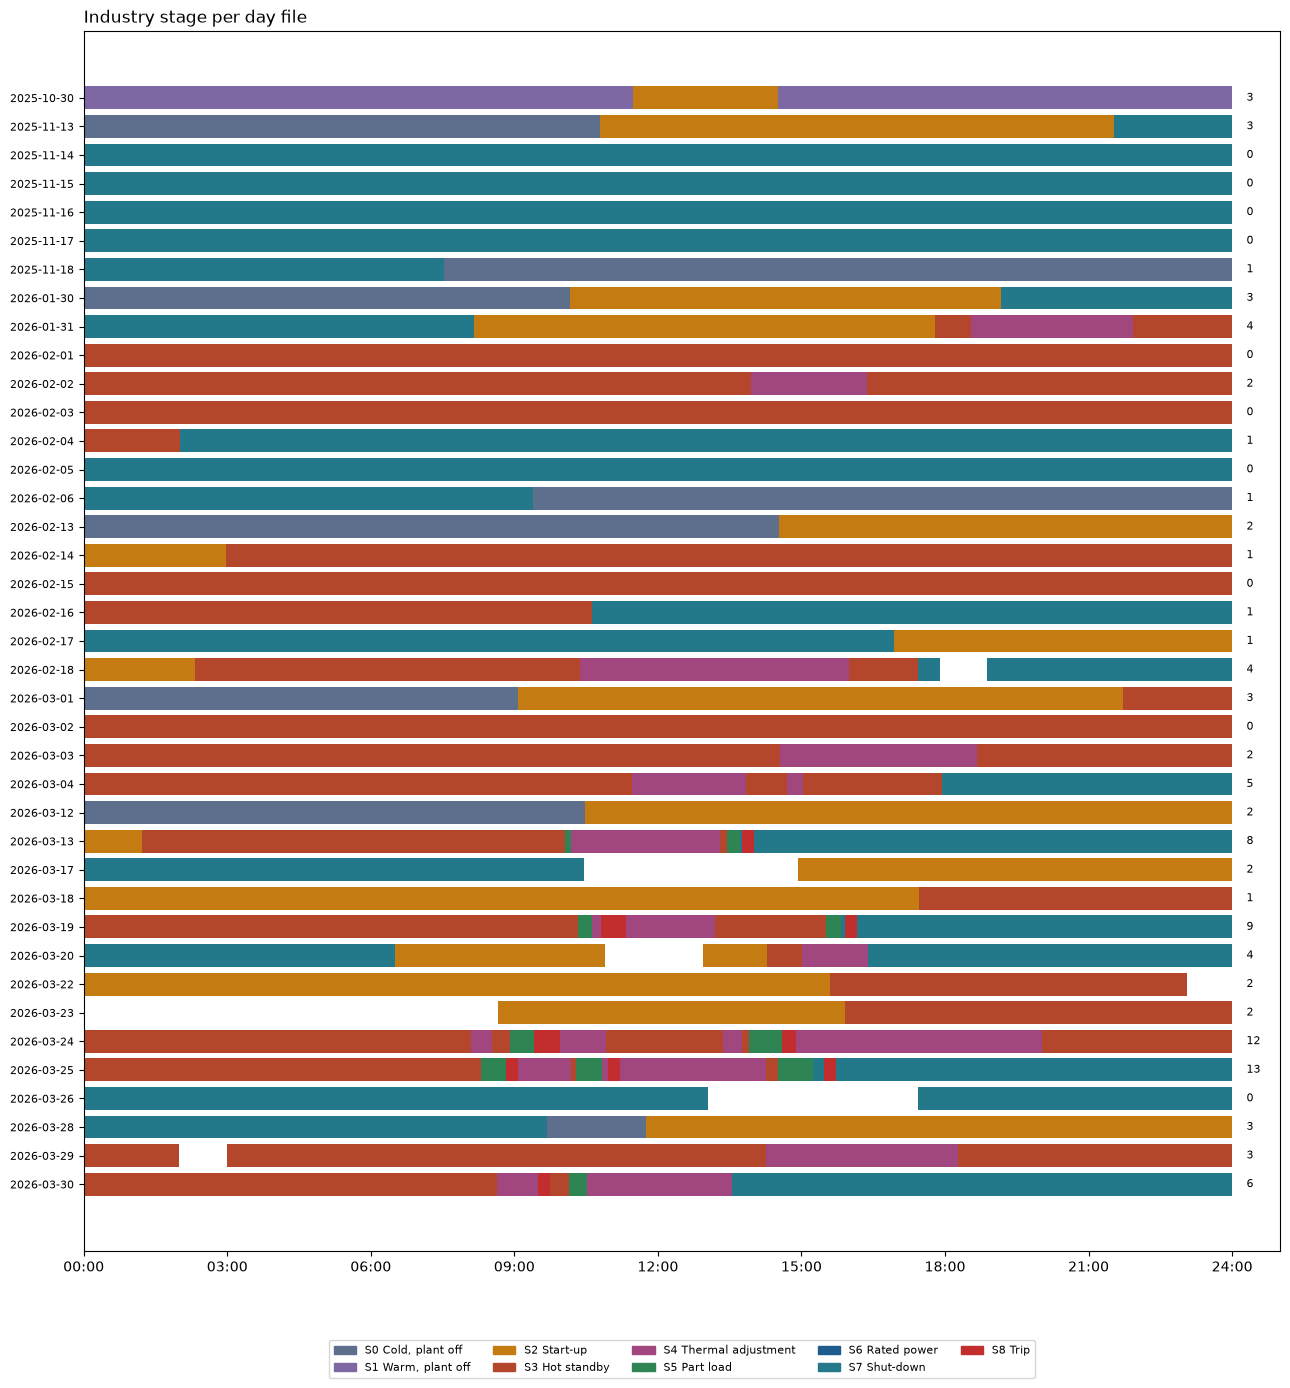

In [14]:
fig, ax = plt.subplots(figsize=(13, 0.32 * len(all_days) + 1.4))
started = eps.groupby(eps.start.dt.strftime("%Y%m%d")).size()
for row, (d, (s, blk)) in enumerate(all_days.items()):
    base = pd.Timestamp(d)
    for r in blk.itertuples():
        ax.barh(
            row,
            (r.end - r.start) / pd.Timedelta("1h"),
            left=(r.start - base) / pd.Timedelta("1h"),
            height=0.8,
            color=ind.COLORS[r.code],
            edgecolor="none",
        )
    ax.text(24.3, row, int(started.get(d, 0)), va="center", fontsize=8)
ax.set_yticks(
    range(len(all_days)),
    [pd.Timestamp(d).strftime("%Y-%m-%d") for d in all_days],
    fontsize=8,
)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
ax.legend(
    handles=ind.legend_handles(),
    ncol=5,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03 - 1.5 / len(all_days)),
)
ax.set_title("Industry stage per day file", loc="left")
plt.tight_layout()
plt.show()

### 6.6 Stretches of consecutive days

The 39 day files form stretches of consecutive days. Each stretch gets one plot on a clock-time axis (thin vertical
line = midnight): stack temperature, heater power and string current, then the industry band and today's stage band (today's colours
as in `operating_states.ipynb`). Trip cuts are marked ▼.

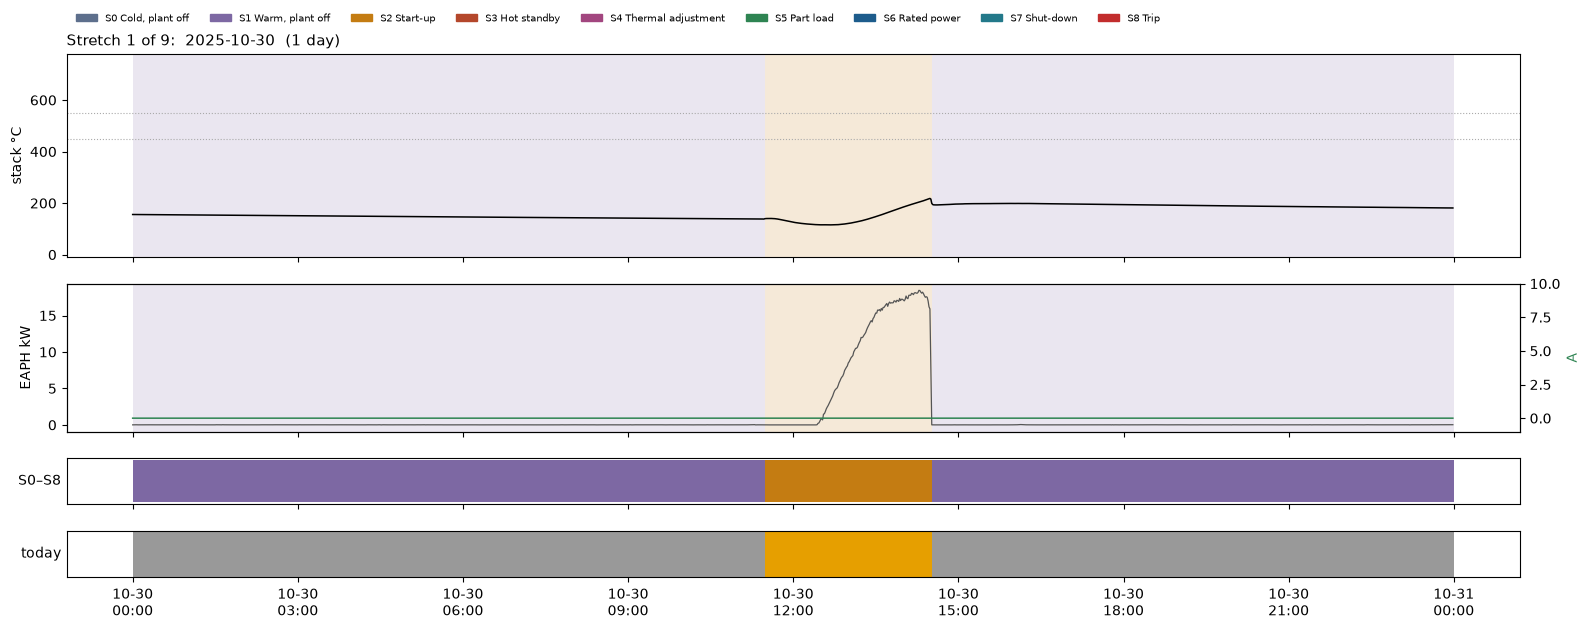

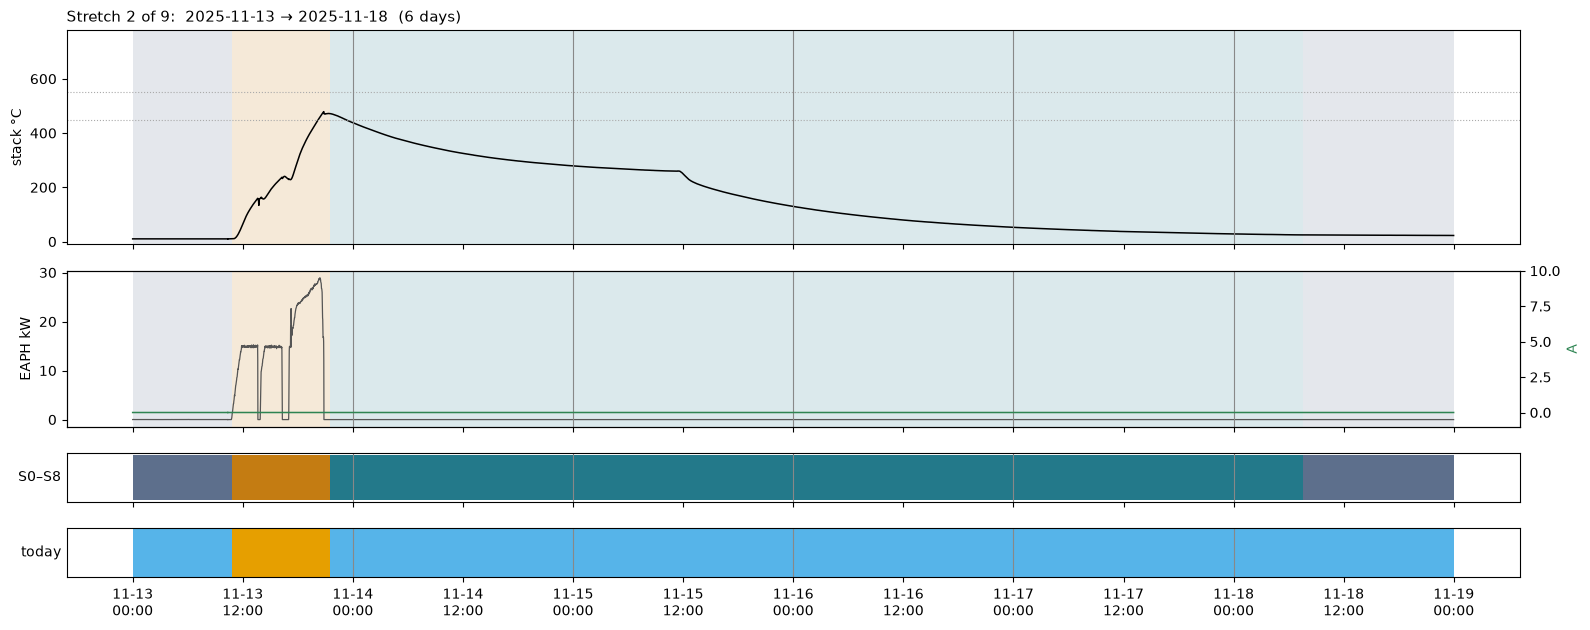

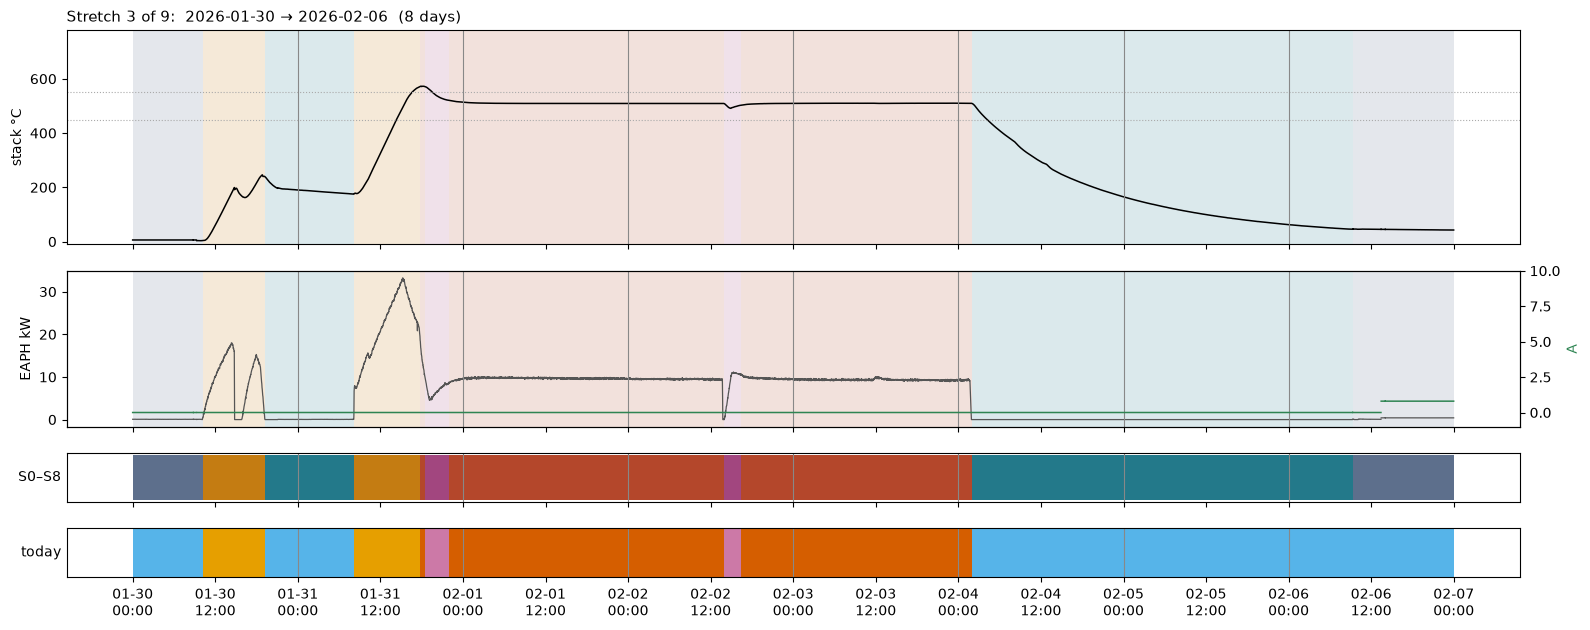

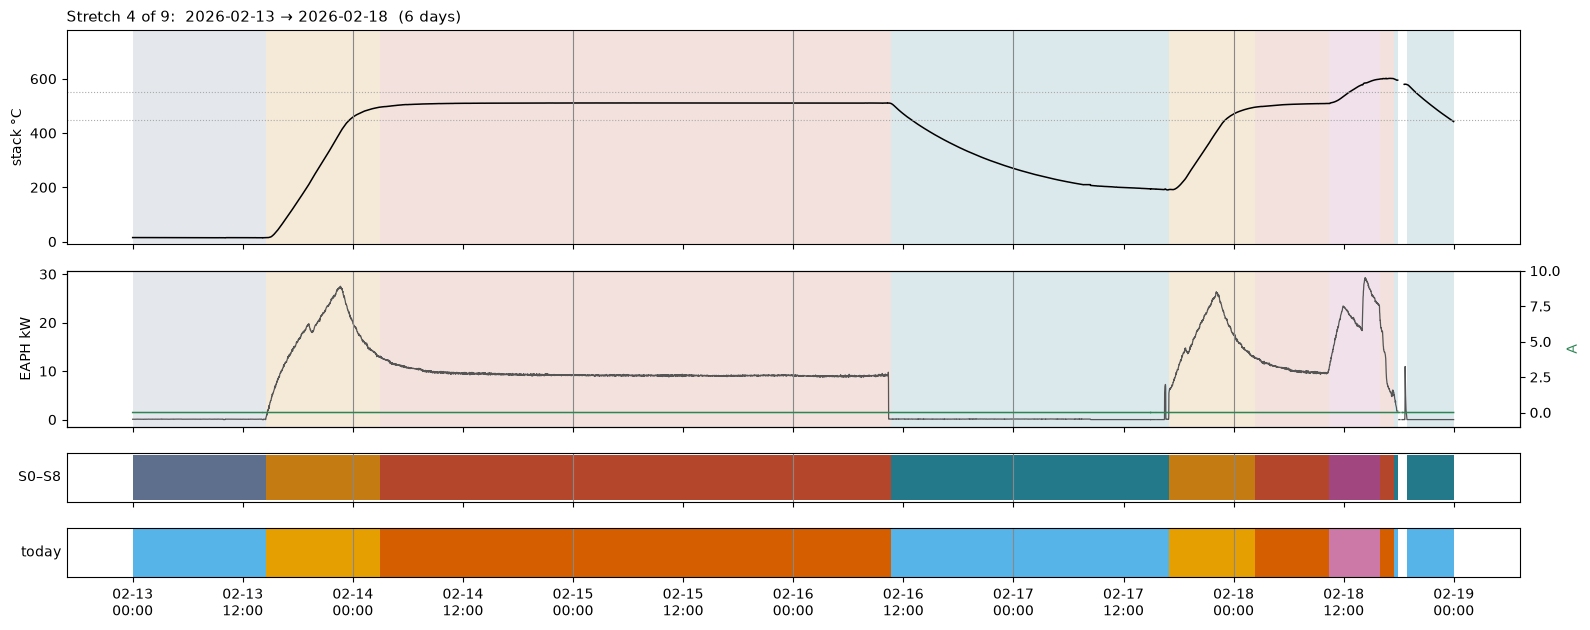

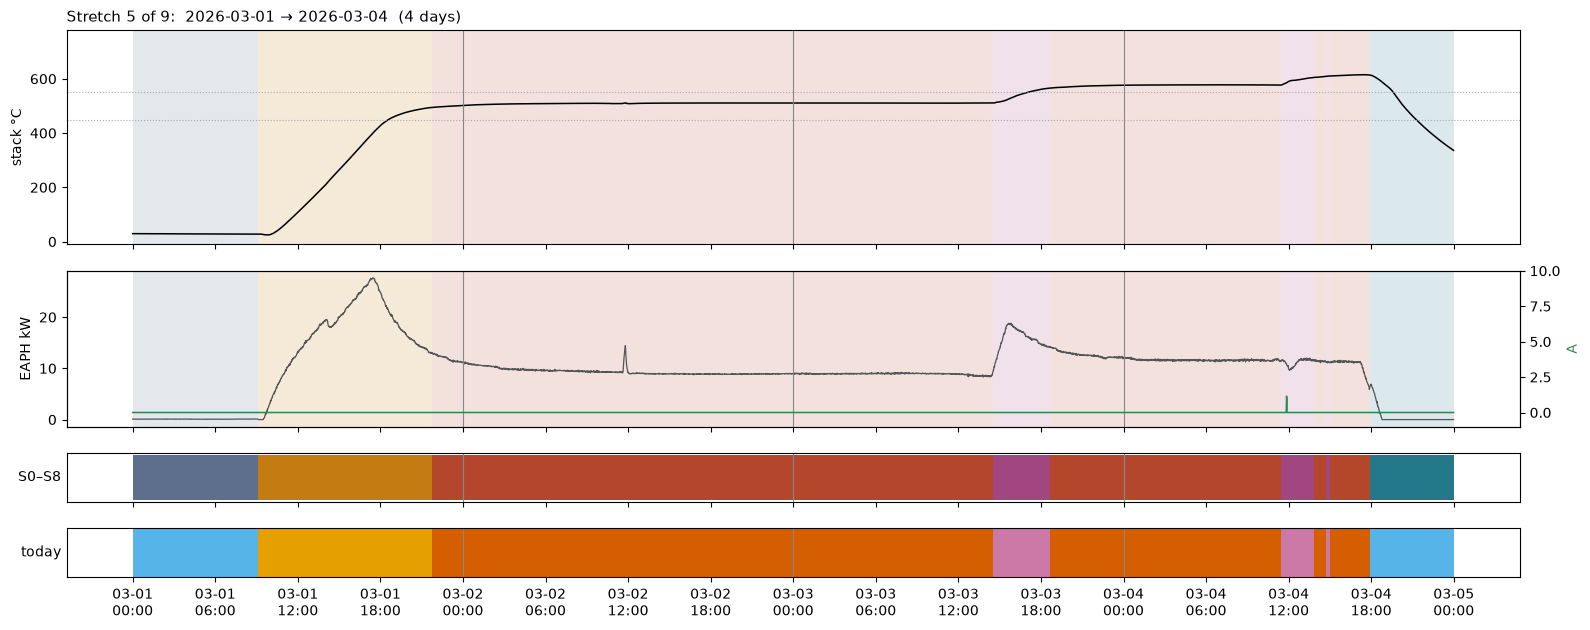

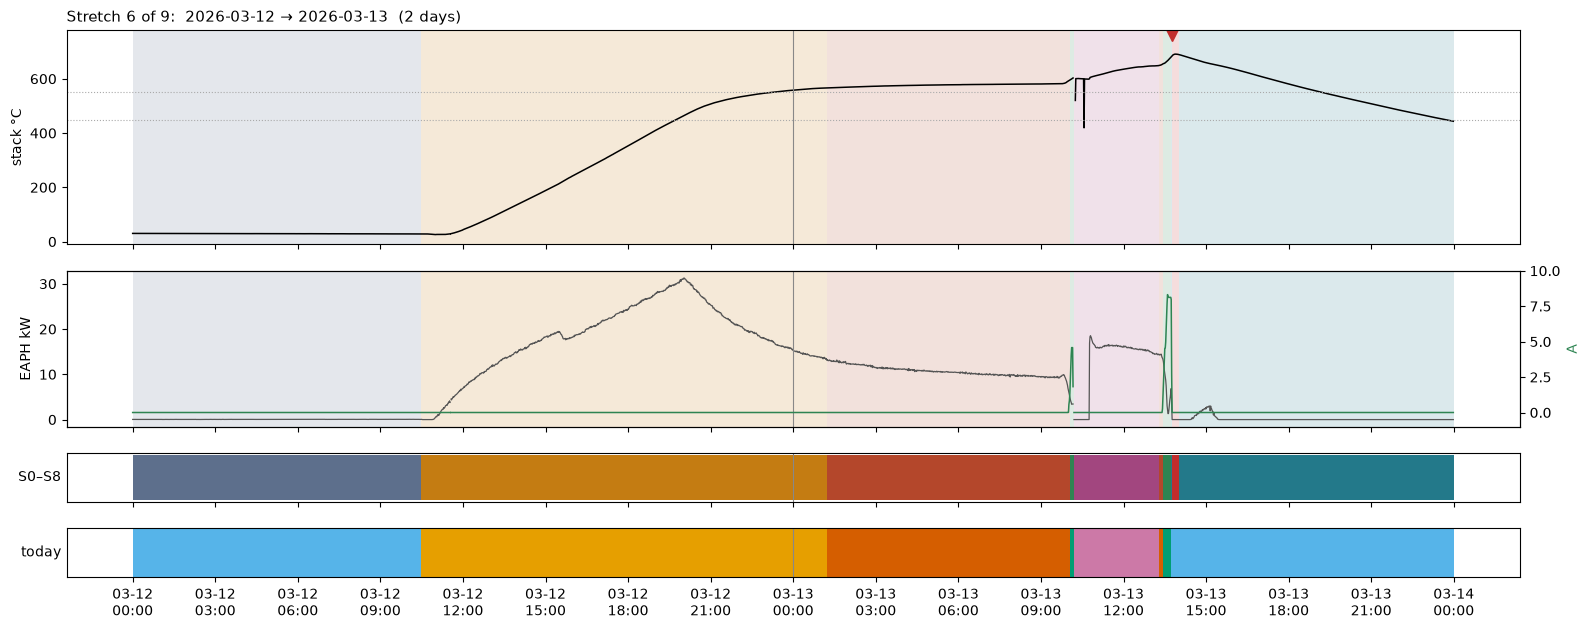

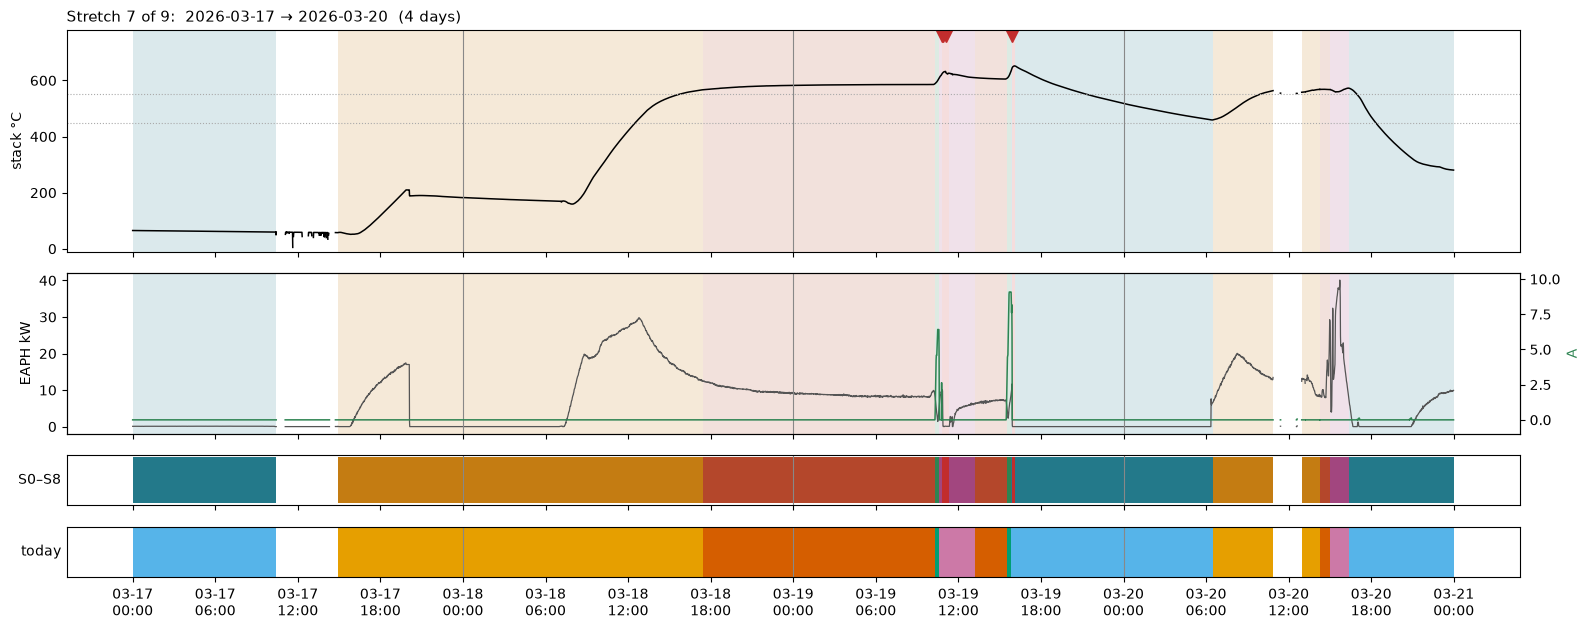

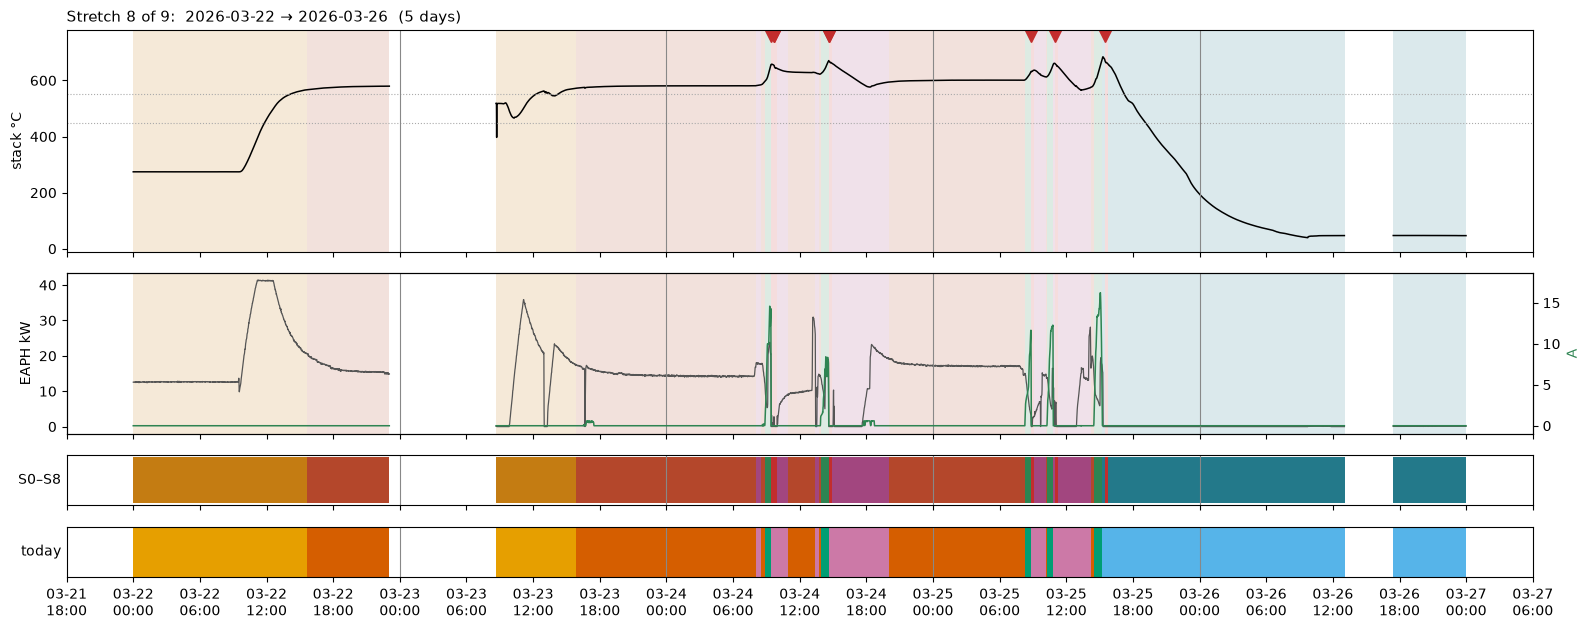

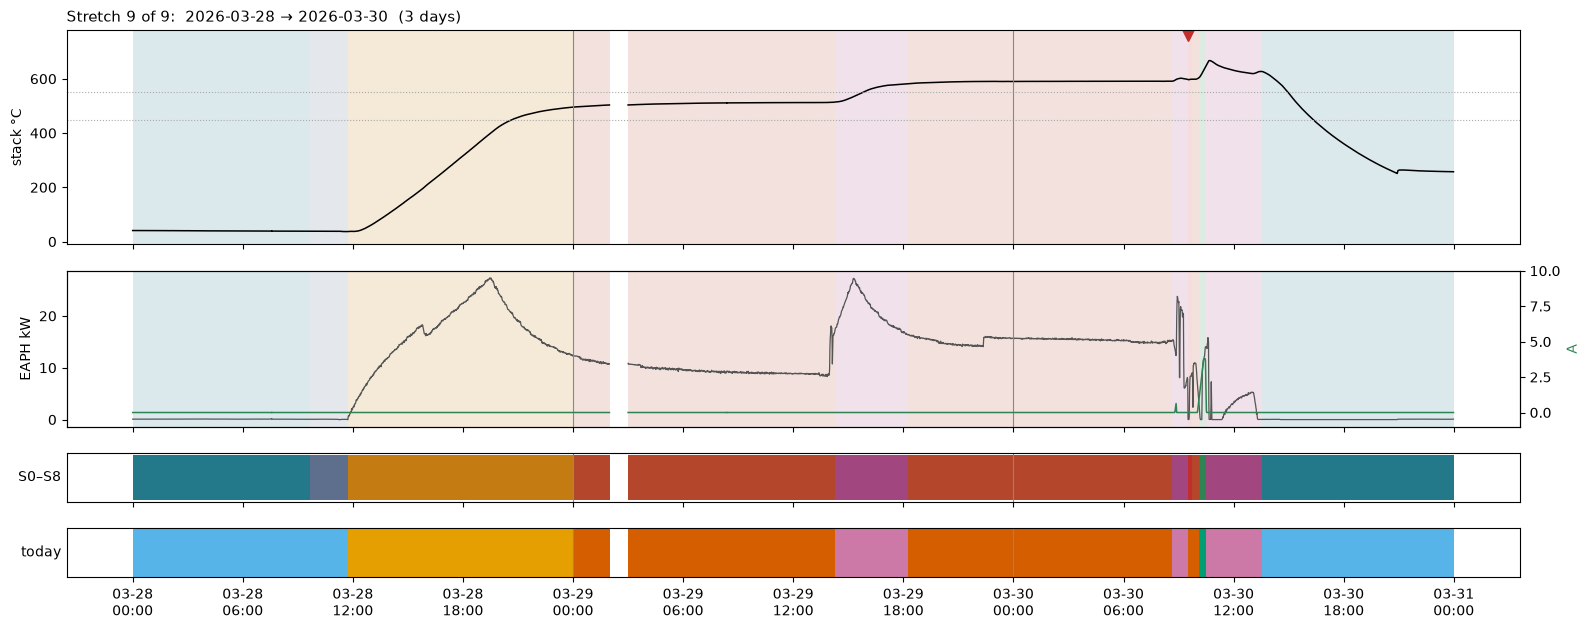

In [15]:
days = list(all_days)
groups = []
for d in days:
    if groups and pd.Timestamp(d) - pd.Timestamp(groups[-1][-1]) == pd.Timedelta("1D"):
        groups[-1].append(d)
    else:
        groups.append([d])

for gi, grp in enumerate(groups, 1):
    t0_, t1_ = pd.Timestamp(grp[0]), pd.Timestamp(grp[-1]) + pd.Timedelta("1D")
    s = pd.concat([all_days[d][0] for d in grp]).reindex(
        pd.date_range(t0_, t1_, freq="1min", inclusive="left")
    )
    blk = pd.concat([all_days[d][1] for d in grp])
    fig, ax = plt.subplots(
        4,
        1,
        figsize=(16, 6.4),
        sharex=True,
        gridspec_kw={"height_ratios": [2.2, 1.6, 0.5, 0.5]},
    )
    ax[0].plot(s.index, s.T_stack_C, "k", lw=1.1)
    for y in (ops.T_HOT, ops.T_STANDBY):
        ax[0].axhline(y, color="#aaa", ls=":", lw=0.8)
    ax[0].set_ylabel("stack °C")
    ax[1].plot(s.index, s.P_EAPH_kW, color="#555", lw=0.9, label="EAPH kW")
    ax[1].set_ylabel("EAPH kW")
    b = ax[1].twinx()
    b.plot(s.index, s.I_string_A, color=ind.COLORS["S5"], lw=1.1)
    b.set_ylabel("A", color=ind.COLORS["S5"])
    b.set_ylim(-1, max(10, np.nanmax(s.I_string_A.values) * 1.15))
    for r in blk.itertuples():
        for a in ax[:2]:
            a.axvspan(r.start, r.end, color=ind.COLORS[r.code], alpha=0.16, lw=0)
    ind.plot_band(ax[2], blk)
    for d in grp:
        sd = all_days[d][0]
        for _, g in sd.groupby(ops.blocks(sd)):
            ax[3].axvspan(
                g.index[0],
                g.index[-1] + pd.Timedelta("1min"),
                color=ops.STAGE_COLORS.get(g.stage.iloc[0], "#fff"),
                lw=0,
            )
    for a, lab in ((ax[2], "S0–S8"), (ax[3], "today")):
        a.set_yticks([])
        a.set_ylabel(lab, rotation=0, ha="right", va="center")
    for t in ev.time[(ev.time >= t0_) & (ev.time < t1_)]:
        ax[0].plot(t, 760, marker="v", color=ind.COLORS["S8"], ms=8)
    for d in grp[1:]:
        for a in ax:
            a.axvline(pd.Timestamp(d), color="#888", lw=0.8)
    ax[0].set_ylim(-10, 780)
    hrs = (t1_ - t0_) / pd.Timedelta("1h")
    ax[-1].xaxis.set_major_locator(
        mdates.HourLocator(
            byhour=range(0, 24, 3 if hrs <= 48 else 6 if hrs <= 120 else 12)
        )
    )
    ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
    ax[0].set_title(
        f"Stretch {gi} of {len(groups)}:  {t0_:%Y-%m-%d}"
        + (f" → {pd.Timestamp(grp[-1]):%Y-%m-%d}" if len(grp) > 1 else "")
        + f"  ({len(grp)} day{'s' * (len(grp) > 1)})",
        loc="left",
        fontsize=11,
    )
    if gi == 1:
        ax[0].legend(
            handles=ind.legend_handles(),
            ncol=9,
            fontsize=7.5,
            loc="lower left",
            bbox_to_anchor=(0, 1.1),
            frameon=False,
        )
    fig.tight_layout()
    plt.show()

### 6.7 Transitions between stages

How often each stage followed another (rows = from, columns = to). "–" = unknown, after a logger gap of more than 6 h or
a missing day file. The industry loop is S0 → S2 → S3 ⇄ S4 / S5 → S7 → S0, with S8 as the fault exit.

In [16]:
tr = pd.crosstab(eps.prev, eps.code)
order = [c for c in ind.CODES + ["–"] if c in set(tr.index) | set(tr.columns)]
tr = tr.reindex(index=order, columns=[c for c in order if c != "–"], fill_value=0)
tr.index.name = "from \\ to"
tr.style.background_gradient(cmap="Blues", axis=None).format("{:d}")

code,S0,S1,S2,S3,S4,S5,S7,S8
from \ to,,,,,,,,
S0,0,0,6,0,0,0,0,0
S1,0,0,1,0,0,0,0,0
S2,0,1,0,10,0,0,2,0
S3,0,0,0,0,11,10,4,0
S4,0,0,0,15,0,0,2,3
S5,0,0,0,0,4,0,3,3
S7,3,0,4,0,0,0,0,3
S8,0,0,0,1,5,0,3,0
–,5,1,2,0,0,0,2,0


### 6.8 Start class of every start-up (decision C)

In [17]:
su = eps[eps.code == "S2"][
    [
        "start",
        "end",
        "minutes",
        "T_start_C",
        "T_amb_C",
        "T_end_C",
        "start_class",
        "prev",
        "next",
    ]
].copy()
su["hours"] = (su.minutes / 60).round(1)
display(
    su.drop(columns="minutes")
    .round({"T_start_C": 1, "T_amb_C": 1, "T_end_C": 1})
    .reset_index(drop=True)
)
su.groupby("start_class").agg(
    starts=("start", "size"),
    mean_hours=("hours", "mean"),
    T_start_min=("T_start_C", "min"),
    T_start_max=("T_start_C", "max"),
).reindex(ind.START_CLASSES).round(1)

,start,end,T_start_C,T_amb_C,T_end_C,start_class,prev,next,hours
0,2025-10-30 11:29:00,2025-10-30 14:31:00,139.5,17.8,215.5,warm,S1,S1,3.0
1,2025-11-13 10:47:00,2025-11-13 21:32:00,10.1,17.6,471.6,cold,S0,S7,10.8
2,2026-01-30 10:10:00,2026-01-30 19:10:00,4.1,16.3,240.5,cold,S0,S7,9.0
3,2026-01-31 08:09:00,2026-01-31 17:47:00,176.0,16.1,571.6,warm,S7,S3,9.6
4,2026-02-13 14:32:00,2026-02-14 02:58:00,14.5,16.6,495.4,cold,S0,S3,12.4
5,2026-02-17 16:56:00,2026-02-18 02:19:00,191.7,15.7,495.2,warm,S7,S3,9.4
6,2026-03-01 09:05:00,2026-03-01 21:43:00,27.5,16.5,494.1,cold,S0,S3,12.6
7,2026-03-12 10:29:00,2026-03-13 01:13:00,28.4,13.9,566.6,cold,S0,S3,14.7
8,2026-03-17 14:56:00,2026-03-18 17:27:00,57.7,15.9,566.8,warm,S7,S3,26.5
9,2026-03-20 06:30:00,2026-03-20 14:17:00,459.5,10.7,568.0,hot,S7,S3,5.7


,starts,mean_hours,T_start_min,T_start_max
start_class,,,,
cold,6,12.0,4.1,37.1
warm,5,12.8,57.7,274.4
hot,2,6.4,459.5,518.3


### 6.9 Every trip (S8), with the stage before and after

In [18]:
s8 = eps[eps.code == "S8"].reset_index(drop=True)
pl = eps[eps.code == "S5"]
trip_tab = trips.assign(
    stage_before=s8.prev.map(ind.LABELS).values,
    stage_after=s8.next.map(ind.LABELS).values,
    T_stack_C=s8.T_start_C.round(0).values,
    last_load_ended=[(pl.end[pl.end <= t].max()) for t in trips.start],
)
trip_tab["min_since_load"] = (
    (trip_tab.start - trip_tab.last_load_ended).dt.total_seconds() / 60
).round(0)
trip_tab["min_since_load"] = trip_tab.min_since_load.where(
    trip_tab.min_since_load < 24 * 60
)  # no load that day: blank
trip_tab[
    [
        "trip",
        "first cut",
        "n cuts",
        "cuts",
        "T_stack_C",
        "stage_before",
        "stage_after",
        "min_since_load",
    ]
]

,trip,first cut,n cuts,cuts,T_stack_C,stage_before,stage_after,min_since_load
0,1,2026-03-13 13:45:15,1,"Power cut at trip value, gas unchanged",683.0,S7 Shut-down,S7 Shut-down,2.0
1,2,2026-03-19 10:49:49,3,"Power cut at trip value, gas unchanged → Power...",624.0,S4 Thermal adjustment,S4 Thermal adjustment,12.0
2,3,2026-03-19 15:54:35,1,"Power cut at trip value, gas unchanged",644.0,S7 Shut-down,S7 Shut-down,5.0
3,4,2026-03-24 09:25:26,3,"EMERGENCY PURGE → Power cut at trip value, gas...",657.0,S5 Part load,S4 Thermal adjustment,0.0
4,5,2026-03-24 14:36:22,2,EMERGENCY PURGE → EMERGENCY STOP,670.0,S5 Part load,S4 Thermal adjustment,0.0
5,6,2026-03-25 08:50:37,1,EMERGENCY STOP,632.0,S5 Part load,S4 Thermal adjustment,0.0
6,7,2026-03-25 10:58:26,1,"Power cut at trip value, gas unchanged",661.0,S4 Thermal adjustment,S4 Thermal adjustment,8.0
7,8,2026-03-25 15:28:17,1,EMERGENCY STOP,673.0,S7 Shut-down,S7 Shut-down,14.0
8,9,2026-03-30 09:30:57,1,EMERGENCY STOP,598.0,S4 Thermal adjustment,S3 Hot standby,NaN


## 7. Save results

In [19]:
ind.OUT.mkdir(parents=True, exist_ok=True)
cols = [
    "T_stack_C",
    "dTdt_20min_C_per_h",
    "I_string_A",
    "P_EAPH_kW",
    "phase",
    "stage",
    "sub_stage",
    "operation",
    "code",
    "ind_stage",
    "trip",
]
allst[cols].to_parquet(ind.OUT / "industrial_states_1min.parquet")
pd.concat({d: b for d, (_, b) in all_days.items()}, names=["day"]).reset_index(
    level=0
).to_csv(ind.OUT / "industrial_blocks.csv", index=False)
eps.drop(columns="day").to_csv(ind.OUT / "industrial_episodes.csv", index=False)
trips.to_csv(ind.OUT / "trip_windows.csv", index=False)
per_day.to_csv(ind.OUT / "industrial_episodes_per_day.csv")
minutes.to_csv(ind.OUT / "industrial_minutes_per_day.csv")
cw.to_csv(ind.OUT / "crosswalk_today_to_code_minutes.csv")
sorted(p.name for p in ind.OUT.iterdir())

['crosswalk_today_to_code_minutes.csv',
 'industrial_blocks.csv',
 'industrial_episodes.csv',
 'industrial_episodes_per_day.csv',
 'industrial_minutes_per_day.csv',
 'industrial_states_1min.parquet',
 'trip_windows.csv']

## 8. Findings

**Hours (39 day files, 913 h):** S7 Shut-down 307 h (33 %), S3 Hot standby 297 h (32 %), S2 Start-up 149 h (16 %),
S0 Cold, plant off 88 h (9.5 %), S4 Thermal adjustment 44 h, S1 Warm, plant off 21 h, S5 Part load 4.4 h,
**S8 Trip 2.8 h**, S6 Rated power 0 h, logger gaps 13 h.

* **The codes change no minute except the trips.** Shut-down splits cleanly into S0 (5,292 min at ambient) and S7
  (18,427 min cooling). The 170 trip minutes come out of Thermal adjustment (107), Shut-down (45), Hot standby (15)
  and Part load (3).
* **S8 Trip: 9 trips, all between 2026-03-13 and 03-30, stack at 598–683 °C** (same count as the benchmark page).
  * 3 cut live load straight out of S5 (2026-03-24 09:25 and 14:36, 03-25 08:50).
  * 3 came while the load was already being taken off, in minutes labelled S7 (03-13 13:45, 03-19 15:54, 03-25 15:28).
    Because S8 starts at the cut, these Part load blocks end in S7, not S8 (see `min_since_load` in 6.9).
  * 3 came with no load, during a re-heat or fuel switch-over (S4: 03-19 10:49, 03-25 10:58, 03-30 09:30).
  * After a trip the plant went to S4 (5), S7 (3) or S3 (1). On 2026-03-30 it was back in Hot standby and on load
    again 38 min after an emergency stop.
* **Part load: 10 episodes, 4.4 h, max 16.2 A.** 3 end directly in a trip, 3 in Shut-down, 4 in Thermal adjustment.
  S6 Rated power is never reached.
* **Start classes: 13 start-ups = 6 cold, 5 warm, 2 hot.**
  * Cold (4–37 °C) all start from S0 and take 9–15 h.
  * Warm (139–274 °C) restart from the cooling tail of a Shut-down or from Idle.
  * Hot: 2026-03-20 (460 °C) and 03-23 (518 °C).
  * The benchmark page said 7 / 4 / 3 with a fixed 60 °C cold edge. Here the edge is ambient + 30 K, the same as S0, so
    2026-03-17 (58 °C, ambient 16 °C) counts as warm. Also, the 03-20 start-up is one episode here because its 2 h logger
    gap is bridged.
* **Transitions follow the industry loop:** S0 → S2 (6), S2 → S3 (10), S3 ⇄ S4 (11 / 15), S3 → S5 (10), S5 → S8 (3),
  S7 → S0 (3). Steps outside the loop:
  * S2 → S1 / S7: three aborted start-ups (2025-10-30, 11-13, 2026-01-30),
  * S7 → S2: four restarts from a warm stack before it reached ambient,
  * S8 → S3: the restart after a trip on 2026-03-30.
* **Still not visible: pre-start checks** (leak test, purge sequence). They are not logged. The closest thing is the
  air purge before heat-up, which stays inside S2.

**Open (benchmark decisions, unchanged):**
* A: put the codes in `operating_states.py` output files?
* B: S8 as a stage or the `trip` flag only?
* C: start-class edges (ambient + 30 K, or fixed 60 °C)?
* D: should S0 become its own stage in the stage folders, generator and checker?

Change `DAY` in the first code cell to look at another day in detail.